# 02 — Exploratory Data Analysis

How does the probability of arriving ≥ 15 minutes late vary with airline, airport, route,
scheduled departure hour and month? Every grouping variable used here is **known before
departure**; the actual-time columns are used only to build the target.

Rates are shown with 95% Wilson confidence intervals and sample sizes so small groups are not
over-read. The dashed line in bar charts is the overall delay rate. Data: labelled flights after
the missing-label policy from `configs/config.yaml` (see `01_data_quality.ipynb`).

**Prediction scope.** The target is `is_delayed = 1` if `arr_delay >= 15` minutes. Under the
configured `exclude` policy, flights without an observed `arr_delay` (cancelled, or departed with
no arrival-delay record) are removed. The model therefore estimates the probability of an
arrival delay of at least 15 minutes **for flights with an observed arrival-delay label**. It does
**not** predict cancellations or diversions, and every rate in this notebook is conditional on
the flight having an observed arrival delay.

**How to read the intervals.** The Wilson intervals treat each flight as an independent trial.
Flights on the same day share weather and knock-on delays (§8 shows day-to-day autocorrelation),
so the true uncertainty is wider than shown. Non-overlapping intervals are therefore a hint, not
proof, of a difference. All comparisons here are **descriptive**: a group's rate also reflects its
mix of routes, carriers, departure hours and months, so differences between groups may be
confounded rather than caused by the grouping variable itself.

In [1]:
import hashlib
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Locate the repo root (folder containing pyproject.toml) so the notebook runs from anywhere.
ROOT = Path.cwd().resolve()
while not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from flight_delay.config import load_config  # noqa: E402

cfg = load_config(ROOT / "configs" / "config.yaml")
RAW_PATH = ROOT / cfg["paths"]["raw"]
THRESHOLD = cfg["target"]["threshold_minutes"]
POLICY = cfg["target"]["cancelled_policy"]

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

# Plot style: one accent hue, neutral ink, recessive grid.
ACCENT, INK, MUTED, GRID = "#2a78d6", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelsize": 9,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
})

print("raw file :", RAW_PATH.relative_to(ROOT))
print("sha256   :", hashlib.sha256(RAW_PATH.read_bytes()).hexdigest())
print(f"target   : arr_delay >= {THRESHOLD} min | missing-label policy: {POLICY}")

raw file : data/raw/flights.csv
sha256   : 8bdc6abbf07ac0cbb1036bc14a787cab3eea616be46c31899d2d8048963b08aa
target   : arr_delay >= 15 min | missing-label policy: exclude


In [2]:
from flight_delay.data.clean import build_labelled_frame
from flight_delay.data.load import load_raw
from flight_delay.data.validate import rate_table

raw = load_raw(RAW_PATH)

# Scheduled congestion: departures scheduled from the same origin, on the same date, in the same
# scheduled hour. Counted on the FULL raw table (including flights later cancelled or without an
# arrival-delay label), because the published schedule is known before departure regardless of
# what later happens to each flight. It must be computed BEFORE the missing-label policy removes
# rows. Feature engineering should use this same definition.
CONGESTION_KEYS = ["origin", "date", "hour"]
raw["sched_dep_per_origin_hour"] = raw.groupby(CONGESTION_KEYS)["id"].transform("size")

df = build_labelled_frame(raw, THRESHOLD, POLICY)
df["is_delayed"] = df["is_delayed"].astype(int)
df["dow"] = df["date"].dt.dayofweek  # 0 = Monday
df["route"] = df["origin"] + "→" + df["dest"]
BASE = df["is_delayed"].mean()
print(f"labelled flights: {len(df):,} | overall delay rate: {BASE:.3f}")


def rate_barh(tab, title, label_col=None, ax=None, height=None):
    """Horizontal bars of delay rate with 95% Wilson CIs and n labels; dashed = overall rate."""
    tab = tab.sort_values("delay_rate")
    labels = tab[label_col] if label_col else tab.index.astype(str)
    if ax is None:
        _, ax = plt.subplots(figsize=(7, height or max(2.5, 0.28 * len(tab))))
    y = np.arange(len(tab))
    ax.barh(y, tab["delay_rate"], color=ACCENT, height=0.62)
    ax.errorbar(tab["delay_rate"], y,
                xerr=[tab["delay_rate"] - tab["ci_low"], tab["ci_high"] - tab["delay_rate"]],
                fmt="none", ecolor=INK, elinewidth=0.8, capsize=2)
    for yi, (r, n) in enumerate(zip(tab["ci_high"], tab["n"])):
        ax.text(r + 0.005, yi, f"n={n:,}", va="center", fontsize=7, color=MUTED)
    ax.axvline(BASE, color=MUTED, ls="--", lw=1)
    ax.set_yticks(y, labels)
    ax.set_xlabel("share of flights arriving ≥15 min late (95% CI)")
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
    ax.set_xlim(0, max(tab["ci_high"].max() + 0.08, BASE + 0.1))
    return ax

labelled flights: 327,346 | overall delay rate: 0.245


## 1. Distribution of arrival delay

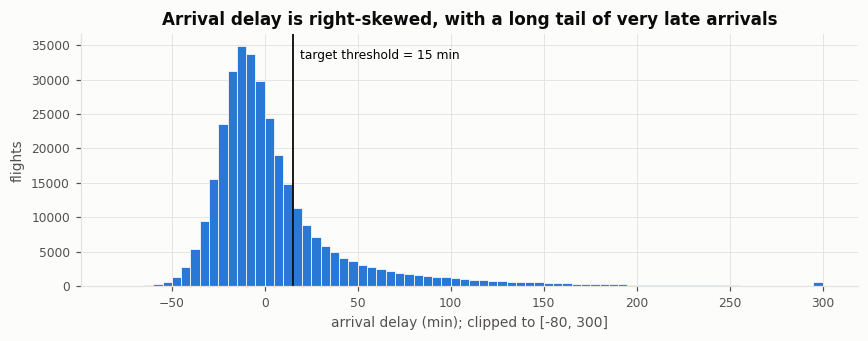

{'count': 327346.0, 'mean': 6.9, 'std': 44.6, 'min': -86.0, '25%': -17.0, '50%': -5.0, '75%': 14.0, 'max': 1272.0}
skewness: 3.72


,share of labelled flights
early (arr_delay < 0),57.7%
exactly on schedule (= 0),1.7%
"late, under threshold (0 < arr_delay < 15)",16.2%
delayed (arr_delay >= 15) — target = 1,24.5%


In [3]:
fig, ax = plt.subplots(figsize=(8, 3.2))
clipped = df["arr_delay"].clip(-80, 300)
ax.hist(clipped, bins=np.arange(-80, 305, 5), color=ACCENT, edgecolor="#fcfcfb", linewidth=0.5)
ax.axvline(THRESHOLD, color=INK, lw=1.2)
ax.text(THRESHOLD + 4, ax.get_ylim()[1] * 0.9, f"target threshold = {THRESHOLD} min", fontsize=8)
ax.set_xlabel("arrival delay (min); clipped to [-80, 300]")
ax.set_ylabel("flights")
ax.set_title("Arrival delay is right-skewed, with a long tail of very late arrivals")
plt.tight_layout()
plt.show()
print(df["arr_delay"].describe().round(1).to_dict())
print("skewness:", round(df["arr_delay"].skew(), 2))

d = df["arr_delay"]
shares = pd.Series({
    "early (arr_delay < 0)": (d < 0).mean(),
    "exactly on schedule (= 0)": (d == 0).mean(),
    "late, under threshold (0 < arr_delay < 15)": ((d > 0) & (d < THRESHOLD)).mean(),
    f"delayed (arr_delay >= {THRESHOLD}) — target = 1": (d >= THRESHOLD).mean(),
}, name="share of labelled flights")
shares.map("{:.1%}".format).to_frame()

## 2. Airline

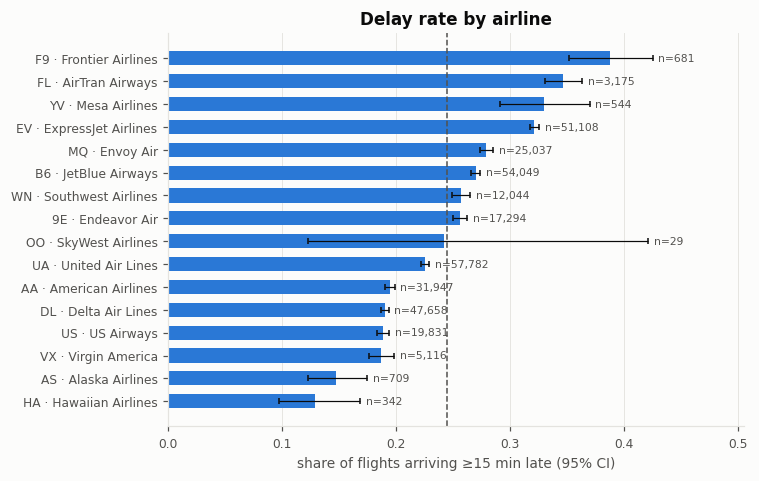

,carrier,name,n,delay_rate,ci_low,ci_high
6,F9,Frontier Airlines Inc.,681,0.388,0.352,0.425
7,FL,AirTran Airways Corporation,3175,0.346,0.330,0.363
15,YV,Mesa Airlines Inc.,544,0.329,0.291,0.370
5,EV,ExpressJet Airlines Inc.,51108,0.321,0.317,0.325
9,MQ,Envoy Air,25037,0.279,0.274,0.285
3,B6,JetBlue Airways,54049,0.270,0.266,0.273
14,WN,Southwest Airlines Co.,12044,0.257,0.249,0.265
0,9E,Endeavor Air Inc.,17294,0.256,0.249,0.262
10,OO,SkyWest Airlines Inc.,29,0.241,0.122,0.421
11,UA,United Air Lines Inc.,57782,0.225,0.222,0.228


In [4]:
car = rate_table(df, ["carrier", "name"]).reset_index()
car["label"] = car["carrier"] + " · " + car["name"].str.replace(r" (Inc\.|Co\.|Corporation|Corp)\.?$", "", regex=True)
rate_barh(car, "Delay rate by airline", label_col="label")
plt.tight_layout()
plt.show()
car.sort_values("delay_rate", ascending=False)[["carrier", "name", "n", "delay_rate", "ci_low", "ci_high"]].round(3)

## 3. Airports

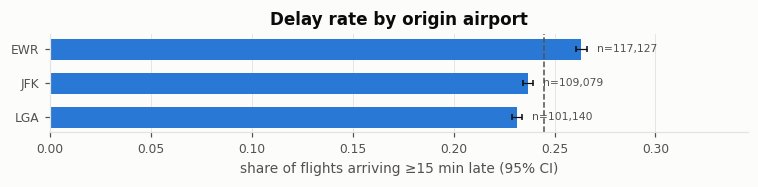

,n,n_delayed,delay_rate,ci_low,ci_high
origin,,,,,
EWR,117127,30847,0.263,0.261,0.266
JFK,109079,25849,0.237,0.234,0.240
LGA,101140,23404,0.231,0.229,0.234


In [5]:
org = rate_table(df, "origin")
rate_barh(org, "Delay rate by origin airport", height=1.8)
plt.tight_layout()
plt.show()
org.round(3)

104 destinations; 12 have < 100 labelled flights


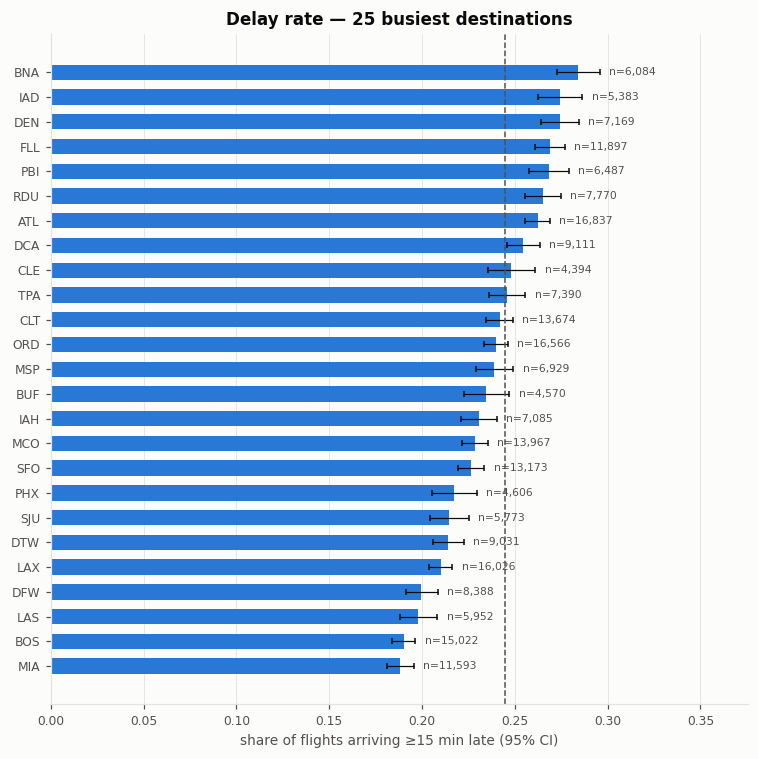

In [6]:
dest_all = rate_table(df, "dest")
print(f"{len(dest_all)} destinations; {(dest_all['n'] < 100).sum()} have < 100 labelled flights")
top_dest = dest_all.nlargest(25, "n")
rate_barh(top_dest, "Delay rate — 25 busiest destinations")
plt.tight_layout()
plt.show()

In [7]:
# Extremes among destinations with enough data (n >= 1,000)
big = dest_all[dest_all["n"] >= 1000].sort_values("delay_rate")
pd.concat([big.head(5), big.tail(5)]).round(3)

,n,n_delayed,delay_rate,ci_low,ci_high
dest,,,,,
MIA,11593,2184,0.188,0.181,0.196
SLC,2451,465,0.190,0.175,0.206
BOS,15022,2855,0.190,0.184,0.196
LAS,5952,1178,0.198,0.188,0.208
SEA,3885,773,0.199,0.187,0.212
CVG,3725,1126,0.302,0.288,0.317
JAX,2623,793,0.302,0.285,0.320
GSO,1492,469,0.314,0.291,0.338
MCI,1885,615,0.326,0.305,0.348


## 4. Routes

223 routes; median labelled flights per route: 752


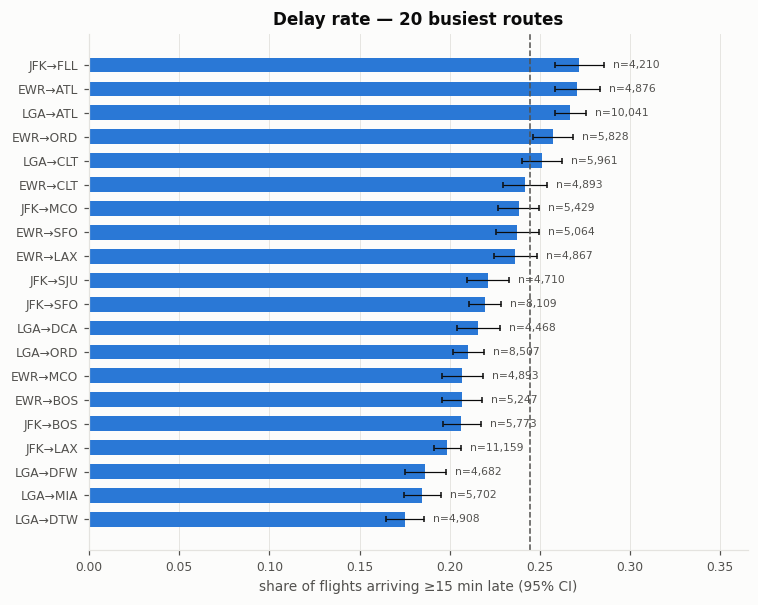

In [8]:
routes = rate_table(df, "route")
print(f"{len(routes)} routes; median labelled flights per route: {routes['n'].median():.0f}")
rate_barh(routes.nlargest(20, "n"), "Delay rate — 20 busiest routes")
plt.tight_layout()
plt.show()

In [9]:
# Same destination, different NYC origin: does the origin change the rate?
top_d = df["dest"].value_counts().head(6).index
pivot = (rate_table(df[df["dest"].isin(top_d)], ["dest", "origin"])["delay_rate"]
         .unstack("origin").round(3))
pivot

origin,EWR,JFK,LGA
dest,,,
ATL,0.271,0.219,0.267
BOS,0.207,0.206,0.145
CLT,0.242,0.223,0.251
LAX,0.236,0.199,NaN
MCO,0.207,0.238,0.244
ORD,0.257,0.308,0.210


## 5. Scheduled departure hour

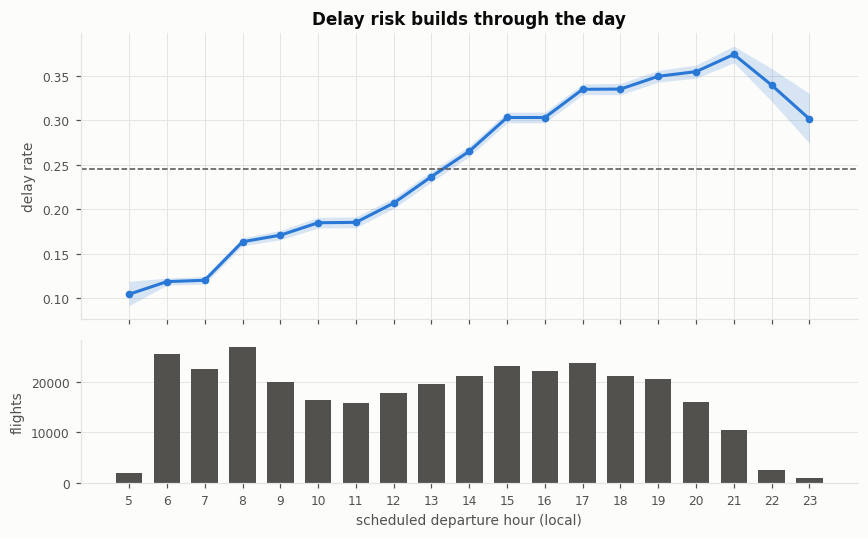

hour,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
n,1940.000,25447.000,22475.00,26734.000,19931.000,16370.000,15689.000,17744.000,19457.000,21022.000,23082.000,22045.000,23667.000,21072.000,20507.000,16061.000,10503.000,2558.000,1042.000
delay_rate,0.105,0.119,0.12,0.163,0.171,0.185,0.185,0.207,0.237,0.265,0.303,0.303,0.335,0.335,0.349,0.354,0.374,0.339,0.301


In [10]:
hr = rate_table(df, "hour")
fig, axes = plt.subplots(2, 1, figsize=(8, 5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
ax = axes[0]
ax.fill_between(hr.index, hr["ci_low"], hr["ci_high"], color=ACCENT, alpha=0.18, lw=0)
ax.plot(hr.index, hr["delay_rate"], color=ACCENT, lw=2, marker="o", ms=4)
ax.axhline(BASE, color=MUTED, ls="--", lw=1)
ax.set_ylabel("delay rate")
ax.set_title("Delay risk builds through the day")
axes[1].bar(hr.index, hr["n"], color=MUTED, width=0.7)
axes[1].set_ylabel("flights")
axes[1].set_xlabel("scheduled departure hour (local)")
axes[1].grid(axis="x", visible=False)
axes[1].set_xticks(range(5, 24))
plt.tight_layout()
plt.show()
hr[["n", "delay_rate"]].T.round(3)

## 6. Month and day of week

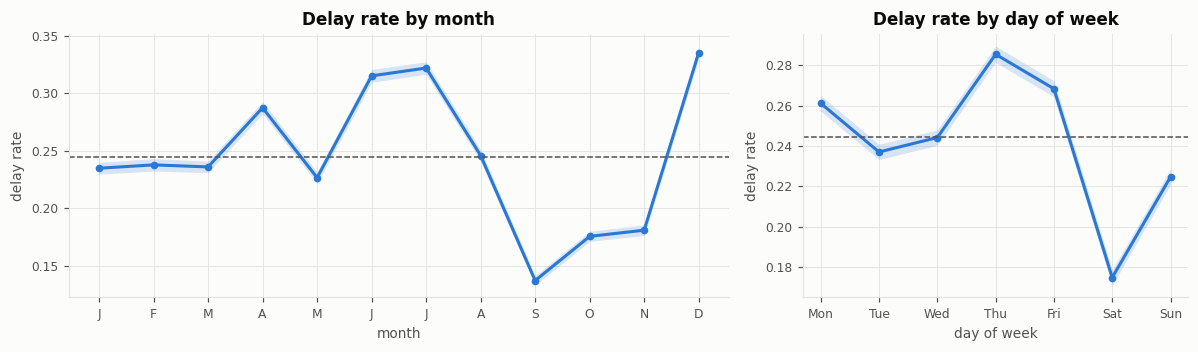

month,1,2,3,4,5,6,7,8,9,10,11,12
n,26398.000,23611.000,27902.000,27564.000,28128.000,27075.000,28293.000,28756.000,27010.000,28618.000,26971.000,27020.000
delay_rate,0.235,0.238,0.236,0.288,0.227,0.315,0.322,0.246,0.137,0.176,0.181,0.335


In [11]:
mo = rate_table(df, "month")
dw = rate_table(df, "dow")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3), gridspec_kw={"width_ratios": [12, 7]})
for ax, t, xl, ticks in [
    (axes[0], mo, "month", list("JFMAMJJASOND")),
    (axes[1], dw, "day of week", ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]),
]:
    ax.fill_between(t.index, t["ci_low"], t["ci_high"], color=ACCENT, alpha=0.18, lw=0)
    ax.plot(t.index, t["delay_rate"], color=ACCENT, lw=2, marker="o", ms=4)
    ax.axhline(BASE, color=MUTED, ls="--", lw=1)
    ax.set_xticks(t.index, ticks)
    ax.set_xlabel(xl)
    ax.set_ylabel("delay rate")
axes[0].set_title("Delay rate by month")
axes[1].set_title("Delay rate by day of week")
plt.tight_layout()
plt.show()
mo[["n", "delay_rate"]].T.round(3)

In [12]:
dw[["n", "delay_rate"]].T.round(3)

dow,0,1,2,3,4,5,6
n,49301.000,49137.000,48632.000,48445.000,48531.000,37794.000,45506.000
delay_rate,0.261,0.237,0.244,0.285,0.268,0.175,0.225


## 7. Interactions

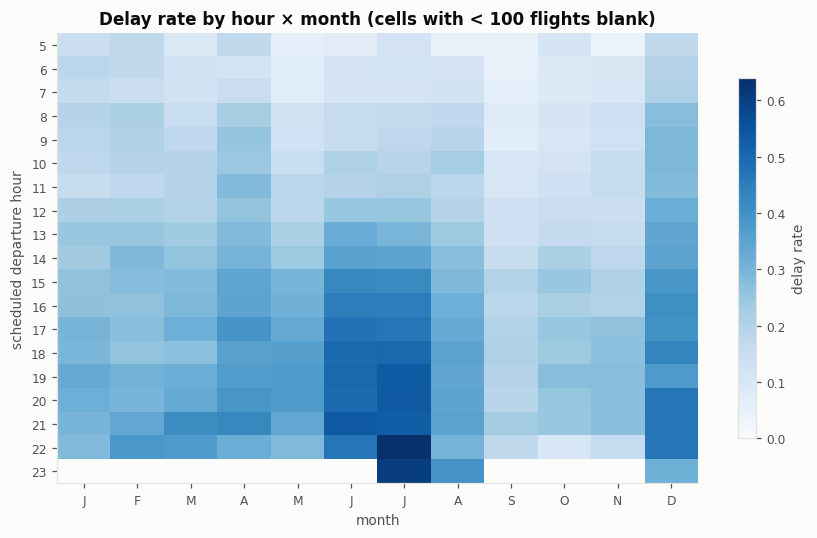

In [13]:
heat = df.pivot_table(index="hour", columns="month", values="is_delayed", aggfunc="mean")
counts = df.pivot_table(index="hour", columns="month", values="is_delayed", aggfunc="size")
heat = heat.where(counts >= 100)  # hide thin cells

fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(heat.values, cmap="Blues", aspect="auto", vmin=0, vmax=np.nanmax(heat.values))
ax.set_xticks(range(12), list("JFMAMJJASOND"))
ax.set_yticks(range(len(heat.index)), heat.index)
ax.set_xlabel("month")
ax.set_ylabel("scheduled departure hour")
ax.set_title("Delay rate by hour × month (cells with < 100 flights blank)")
ax.grid(False)
fig.colorbar(im, ax=ax, label="delay rate", shrink=0.8)
plt.tight_layout()
plt.show()

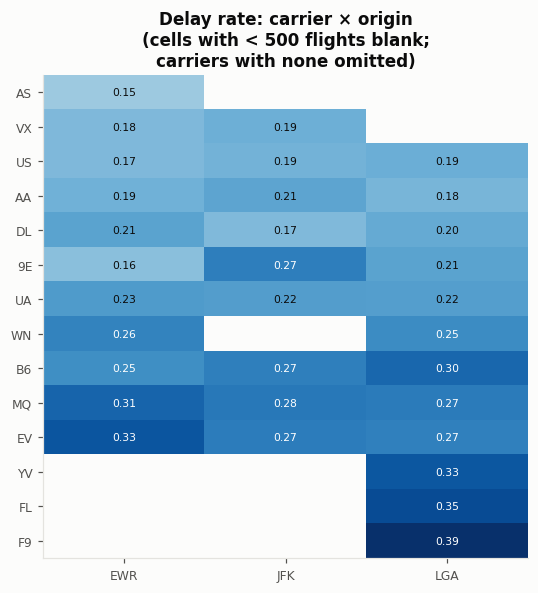

In [14]:
co = df.pivot_table(index="carrier", columns="origin", values="is_delayed", aggfunc="mean")
cn = df.pivot_table(index="carrier", columns="origin", values="is_delayed", aggfunc="size")
co = co.where(cn >= 500).dropna(how="all")  # drop carriers with no cell >= 500
co = co.loc[co.mean(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(5, 5.5))
im = ax.imshow(co.values, cmap="Blues", aspect="auto", vmin=0, vmax=np.nanmax(co.values))
for i in range(co.shape[0]):
    for j in range(co.shape[1]):
        v = co.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if v > 0.6 * np.nanmax(co.values) else INK)
ax.set_xticks(range(co.shape[1]), co.columns)
ax.set_yticks(range(co.shape[0]), co.index)
ax.set_title("Delay rate: carrier × origin\n(cells with < 500 flights blank;\ncarriers with none omitted)")
ax.grid(False)
plt.tight_layout()
plt.show()

## 8. Temporal dependence

If bad days cluster, recent delay history is informative — which motivates the
*past-dates-only* historical features in the feature-engineering stage.

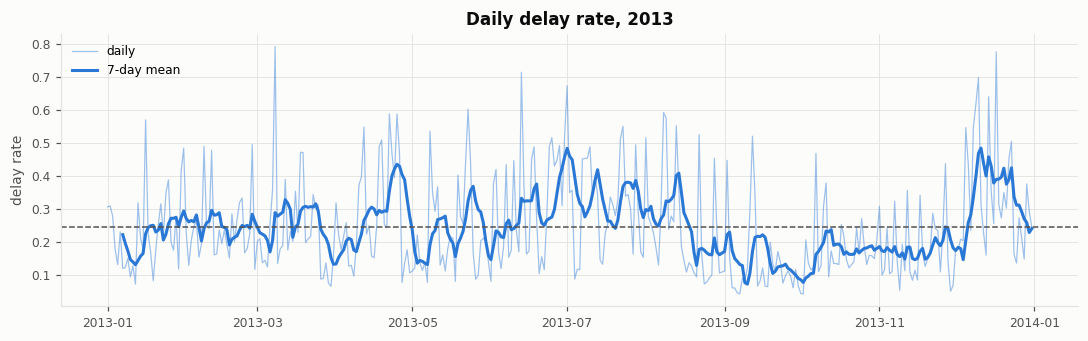

autocorrelation of daily delay rate at lag 1: 0.398
autocorrelation of daily delay rate at lag 2: 0.128
autocorrelation of daily delay rate at lag 7: 0.112
days with delay rate > 50%: 27


,n,rate
date,,
2013-03-08,798,0.792
2013-12-17,835,0.776
2013-06-13,881,0.714
2013-12-10,739,0.698
2013-07-01,877,0.673


In [15]:
daily = df.groupby("date").agg(n=("is_delayed", "size"), rate=("is_delayed", "mean"))
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(daily.index, daily["rate"], color=ACCENT, lw=0.8, alpha=0.45, label="daily")
ax.plot(daily.index, daily["rate"].rolling(7).mean(), color=ACCENT, lw=2, label="7-day mean")
ax.axhline(BASE, color=MUTED, ls="--", lw=1)
ax.set_ylabel("delay rate")
ax.set_title("Daily delay rate, 2013")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

for lag in [1, 2, 7]:
    print(f"autocorrelation of daily delay rate at lag {lag}: {daily['rate'].autocorr(lag):.3f}")
print("days with delay rate > 50%:", int((daily["rate"] > 0.5).sum()))
daily.nlargest(5, "rate").round(3)

## 9. Scheduled congestion and distance

In [16]:
# Scheduled departures per origin per hour, counted on the full raw schedule (see setup cell)
print("rows with all-flights count > labelled-only count:",
      int((df["sched_dep_per_origin_hour"] > df.groupby(CONGESTION_KEYS)["id"].transform("size")).sum()),
      f"of {len(df):,}")
df["congestion_bin"] = pd.qcut(df["sched_dep_per_origin_hour"], 5, duplicates="drop")
cong = rate_table(df, "congestion_bin")
print("Spearman ρ (hourly scheduled departures, delayed):",
      round(df[["sched_dep_per_origin_hour", "is_delayed"]].corr("spearman").iloc[0, 1], 3))
top_hours = (df.groupby("congestion_bin", observed=True)["hour"]
             .agg(lambda s: ", ".join(f"{h}:00 {p:.0%}" for h, p in s.value_counts(normalize=True).head(3).items())))
display(top_hours.to_frame("three most common scheduled hours"))
cong.round(3)

rows with all-flights count > labelled-only count: 80649 of 327,346
Spearman ρ (hourly scheduled departures, delayed): 0.009


,three most common scheduled hours
congestion_bin,
"(0.999, 16.0]","21:00 14%, 10:00 13%, 12:00 11%"
"(16.0, 19.0]","9:00 14%, 14:00 11%, 6:00 9%"
"(19.0, 22.0]","18:00 13%, 7:00 11%, 14:00 11%"
"(22.0, 25.0]","15:00 13%, 17:00 11%, 19:00 10%"
"(25.0, 38.0]","8:00 28%, 6:00 25%, 17:00 11%"


,n,n_delayed,delay_rate,ci_low,ci_high
congestion_bin,,,,,
"(0.999, 16.0]",72874,15747,0.216,0.213,0.219
"(16.0, 19.0]",58840,14480,0.246,0.243,0.250
"(19.0, 22.0]",80899,21940,0.271,0.268,0.274
"(22.0, 25.0]",54412,14999,0.276,0.272,0.279
"(25.0, 38.0]",60321,12934,0.214,0.211,0.218


In [17]:
df["distance_bin"] = pd.qcut(df["distance"], 10, duplicates="drop")
dist = rate_table(df, "distance_bin")
dist.round(3)

,n,n_delayed,delay_rate,ci_low,ci_high
distance_bin,,,,,
"(79.999, 214.0]",32864,7580,0.231,0.226,0.235
"(214.0, 431.0]",35843,9586,0.267,0.263,0.272
"(431.0, 569.0]",31734,7851,0.247,0.243,0.252
"(569.0, 738.0]",31271,8196,0.262,0.257,0.267
"(738.0, 888.0]",32913,9093,0.276,0.271,0.281
"(888.0, 1028.0]",33367,8180,0.245,0.241,0.250
"(1028.0, 1096.0]",33085,7743,0.234,0.230,0.239
"(1096.0, 1598.0]",32983,7835,0.238,0.233,0.242
"(1598.0, 2446.0]",30649,6833,0.223,0.218,0.228


Note: congestion counts **all scheduled departures** in the origin/date/hour slot from the raw
table, including flights that were later cancelled or have no arrival-delay label. The count is
computed before the missing-label policy is applied, so it reflects the published schedule rather
than only the flights that kept a label. It is a descriptive, hour-level association and is
confounded with departure hour (busy banks are concentrated in particular times of day).

## Findings (from the outputs above)

All rates below are for the 327,346 flights with an observed arrival-delay label (`exclude` policy); overall delay rate 24.5%.
**Scope:** the model predicts arrival delay ≥ 15 min *for flights with an observed arrival-delay label*. It does not predict cancellations or diversions.
**Interpretation:** every comparison below is descriptive. Confidence intervals assume independent flights, which understates uncertainty given same-day clustering (item 7), and group differences may reflect the route, carrier, hour and month mix rather than the grouping variable itself.

0. **Arrival-delay distribution.** 57.7% of labelled flights arrive before schedule (`arr_delay < 0`), 1.7% exactly on schedule, 16.2% late by under 15 min, and 24.5% late by 15 min or more (target = 1). The distribution is right-skewed (skewness 3.72; 99th percentile 190 min).

1. **Time of day shows the clearest gradient.** The delay rate rises almost monotonically from 10.5% for 05:00 departures to 37.4% at 21:00, then falls slightly (33.9% at 22:00, 30.1% at 23:00, on far fewer flights). This is consistent with delays propagating through the day.
2. **Strong seasonality.** By month, the delay rate is highest in December (33.6%), July (32.2%) and June (31.5%), and lowest in September (13.7%), October (17.6%) and November (18.1%). The hour × month heatmap shows the evening effect is amplified in summer and December.
3. **Day of week:** Thursday is worst (28.5%) and Saturday best (17.5%). Saturday also has the fewest flights (37,794 vs ~48–49k on weekdays).
4. **Observed delay rates vary across airlines.** Among carriers with large samples, ExpressJet (EV, 32.1%, n = 51,108) and Envoy (MQ, 27.9%) are highest; Delta (19.0%), American (19.4%) and US Airways (18.8%) are lowest. Frontier (38.8%), AirTran (34.6%) and Mesa (32.9%) are also high but on smaller samples. SkyWest (OO) has only 29 labelled flights, so its CI spans 12–42% and its rate should not be interpreted. Carriers fly different routes, hubs and departure times (e.g. regional carriers EV/MQ/9E operate many short, late-day flights), so these gaps are not a like-for-like ranking of airline punctuality.
5. **Origin airport:** EWR's observed rate (26.3%) is higher than JFK's (23.7%) and LGA's (23.1%). The intervals do not overlap, but because they ignore same-day clustering and each airport has a different carrier and destination mix, this is a descriptive difference, not evidence that the airport itself causes more delay. The carrier × origin heatmap shows the origin effect is **not uniform** across carriers (e.g. 9E is 16% at EWR but 27% at JFK; DL is lowest at JFK). This suggests interactions that a purely additive model may miss, and is relevant to the Logistic Regression vs XGBoost comparison.
6. **Destinations and routes:** among destinations with ≥ 1,000 flights, rates range from 18.8% (MIA) to 36.6% (RIC). There are 223 routes (median 752 flights each). The same destination can differ by origin, e.g. ORD: JFK 30.8% vs LGA 21.0%; BOS: LGA 14.5% vs EWR/JFK ~20.7%. These pairs are served by different carriers and schedules, so the origin difference is not isolated. 12 destinations have < 100 flights, so per-destination statistics need smoothing or a minimum count.
7. **Delays cluster in time.** The daily delay rate has lag-1 autocorrelation **0.40** (lag-2: 0.13; lag-7: 0.11), and 27 days have more than half of flights delayed (worst: 2013-03-08 at 79%). Recent-history features computed from **past dates only** should carry signal; same-day realised delays must not be used.
8. **Scheduled congestion has a non-monotonic, confounded relationship with delay.** Congestion is counted as **all scheduled departures** per origin, date and hour on the full raw table, before unlabelled rows are removed. This corrects an earlier version that counted only labelled flights and undercounted 80,649 of the 327,346 rows. Across quintiles the delay rate rises from 21.6% (≤ 16 departures/hour) to 27.6% (23–25), then falls to 21.4% in the busiest quintile (26–38). The overall Spearman ρ is 0.009. About half of the busiest quintile is 06:00 and 08:00 departures, which have low delay rates, so congestion is entangled with departure hour and should be read jointly with it.
9. **Distance has a weak, non-monotonic relationship** with delay: 22–28% across deciles, lowest for the longest flights (> 2,446 mi: 22.1%).

## Implications for feature engineering (for the feature owner to decide)
- Scheduled hour (with cyclic encoding), month and day of week are clearly informative.
- Carrier, origin and destination should be kept, along with carrier × origin and route-level information; the heatmap shows interactions.
- Past-only rolling delay rates should be built per carrier, origin, destination and route.
- Small groups (rare destinations, OO, HA) need minimum-count thresholds or shrinkage.

## Limitations
- These are descriptive, univariate or two-way associations, not causal effects; for example, carrier rates are partly driven by carriers' hour and route mix.
- Congestion is computed from the full raw schedule (origin × date × scheduled hour, all flights including later-cancelled ones). Feature engineering should reuse exactly this definition. Since it uses only the published schedule, it is available before departure.
- Wilson intervals assume independent flights; same-day clustering makes them too narrow.
- Rates are conditional on an observed arrival-delay label; flights that were cancelled or have no arrival record are outside the prediction scope.
- One year of NYC departures. Seasonal conclusions rest on a single occurrence of each month.